# Agent 1: DailyTechUpgradeAgent

CMPE 256, SJSU, Fall 2026. **Goal: become a better technical learner every day.**

The agent finds the three most useful technical articles published in the last few days by authoritative sources, summarizes each one, explains why it matters for my interests and career goals, and packages them as a 15–20 minute daily brief. It learns from my ratings and reading history.

This notebook covers all five assignment deliverables for Agent 1:

| # | Deliverable | Section |
|---|---|---|
| 1 | Agent goals: purpose and expected outcomes | [1. Agent goals](#1.-Agent-goals) |
| 2 | Architecture diagram: workflow, tools, data sources, memory | [2. Architecture](#2.-Architecture) |
| 3 | Working prototype | [3. Working prototype](#3.-Working-prototype) |
| 4 | Sample results: daily technical recommendations | [4. Sample results](#4.-Sample-results) |
| 5 | Evaluation: effectiveness, accuracy, user progress | [5. Evaluation](#5.-Evaluation) |

Full design notes: [ARCHITECTURE.md](ARCHITECTURE.md). To re-run: copy `.env.example` (repo root) to `.env`, fill in the API keys, then run this notebook from this folder with the repo's `.venv` kernel.

## 1. Agent goals

**Purpose.** Turn the flood of AI/ML and physics publishing into a short, trustworthy daily learning session that is tuned to me: an MS Software Engineering student with a BS in Astrophysics, aiming for an ML/AI internship and physics/astrophysics research.

**Expected outcome each day:** a *Daily Tech Brief* (`briefs/YYYY-MM-DD.md`) with the top 3 articles, each with:

- title, source, publication date and URL, taken from the feed or search result (never written by the LLM)
- a technical summary and 3–5 key takeaways
- *why it matters for me*: tied to my interests, skill levels and career goals
- one question to think about, and a suggested reading scope that fits the time budget

**Expected outcome over time:** the agent avoids repeats, favors topics I rate highly or tag `more`, moves away from topics I tag `less`, and steers toward profile interests it hasn't covered recently.

**How each assignment requirement is met:**

| Requirement | How the agent meets it |
|---|---|
| Three relevant, high-quality articles every day | Candidates from 20 RSS/Atom feeds, domain-restricted Tavily search and the arXiv API; an LLM scores relevance, depth and novelty; code adds source authority and recency; top 3 with one per source and distinct topics |
| Summaries with key insights and takeaways | `summarize_and_personalize` writes a summary and 3–5 takeaways from the article's full text |
| Titles, dates, sources, URLs | Inserted by code from tool results; checked against the live page in the evaluation |
| How each article helps my knowledge and career | *Why it matters* section per article, grounded in `profile.json` |
| Personalized to interests and learning progress | Weighted interests and skill levels, ratings and `more`/`less` tags, under-covered interests, near-duplicate filter |
| 15–20 minute brief | Reading time from word count (230 wpm) plus about 5 minutes for the brief; long papers get a suggested section scope |

**Success criteria** (measured in section 5): every day produces 3 articles; 100% of references verified; summaries faithful to the source (judge score ≥ 4/5); most picks rated ≥ 4; briefs within 15–20 minutes; all profile interests covered over time.

## 2. Architecture

The agent is a **LangGraph `StateGraph`**: a fixed pipeline with one retry loop (`broaden_queries`) and one human-in-the-loop step (`collect_feedback`, an `interrupt()`). The LLM is used only where judgment is needed (planning searches, scoring, summarizing); fetching, filtering and metadata are plain code so references stay accurate.

### 2.1 Workflow, tools and memory

The diagram below is rendered from the Mermaid source in [ARCHITECTURE.md](ARCHITECTURE.md). Solid arrows are the graph's control flow; dotted arrows show which nodes call which tools and memory stores.

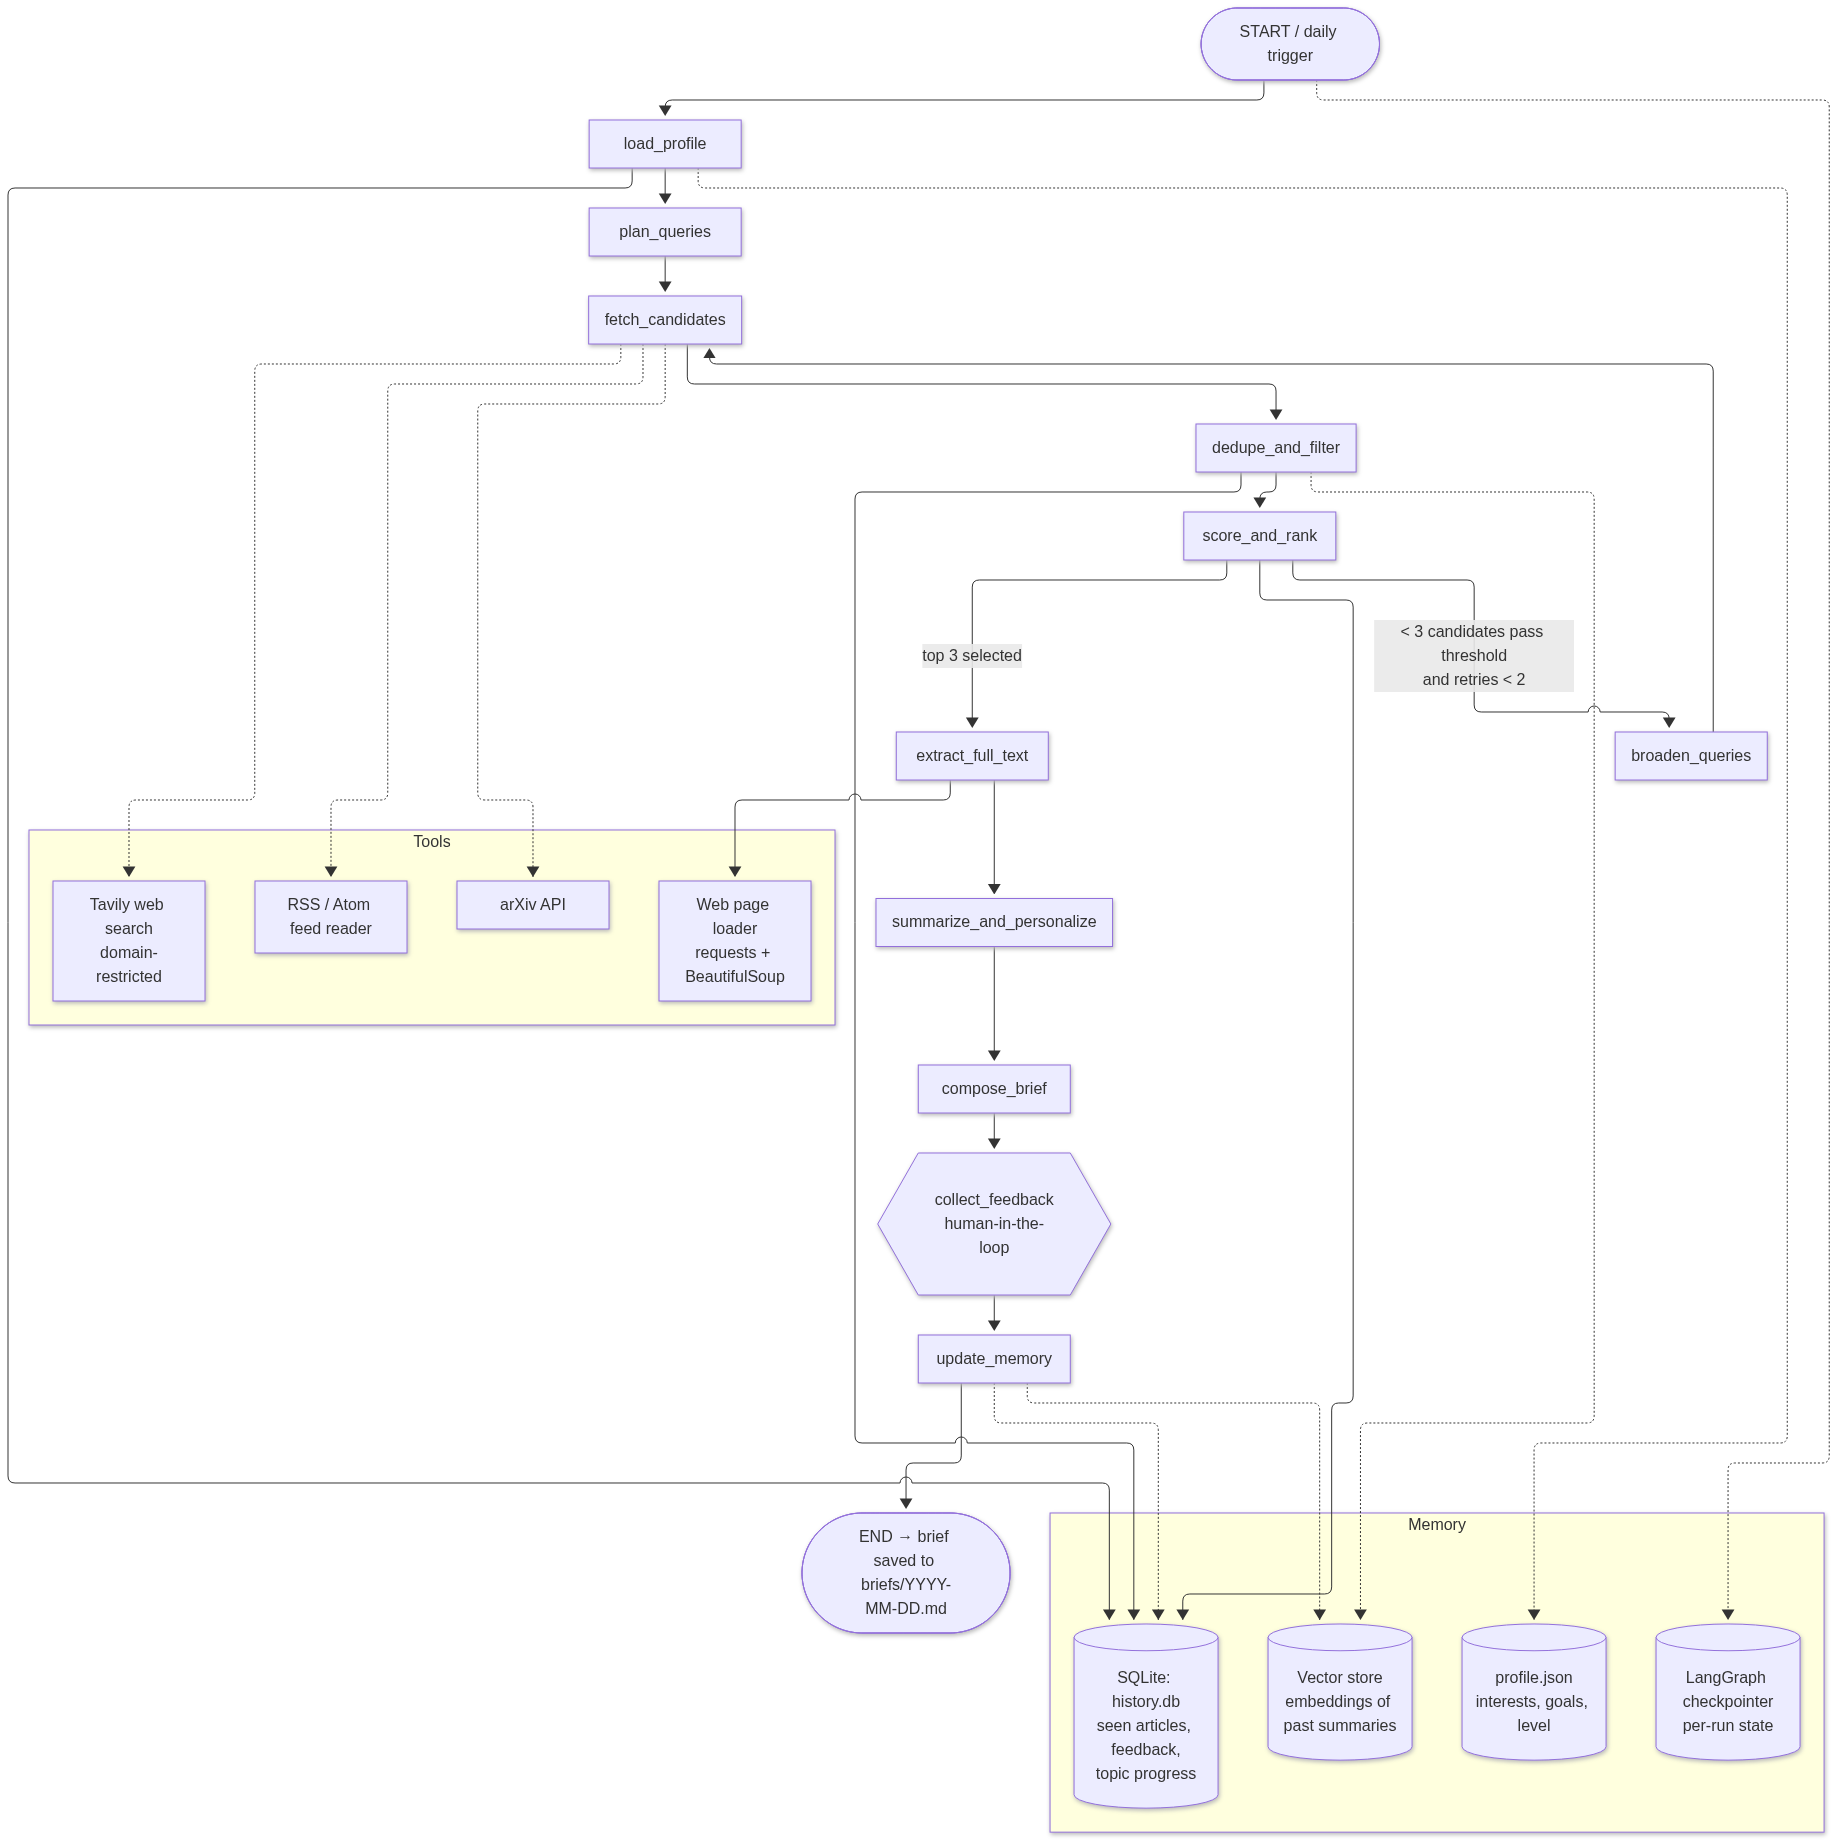

In [1]:
import re
from pathlib import Path

from IPython.display import Image, Markdown, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

architecture_mermaid = re.search(r"```mermaid\n(.*?)```", Path("ARCHITECTURE.md").read_text(), re.S).group(1)
try:
    display(Image(draw_mermaid_png(architecture_mermaid)))
except Exception as exc:   # rendering uses the mermaid.ink web service
    print(f"Could not render the diagram ({exc}); Mermaid source:\n")
    print(architecture_mermaid)

### 2.2 The compiled graph

The same workflow drawn from the actual compiled LangGraph object, which confirms the code matches the design. The dotted edges out of `score_and_rank` are the conditional route: retry with broader queries, or continue with the top 3.

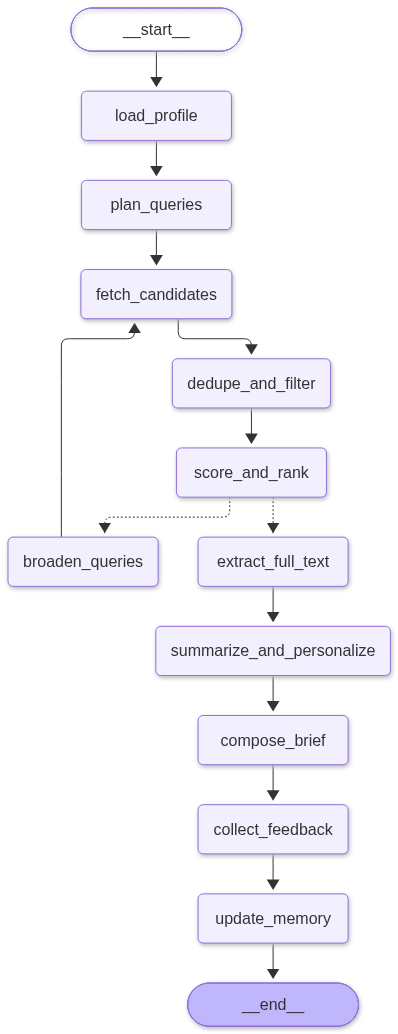

In [2]:
import sys
from datetime import date

import config
import evaluate
import memory
from agent import build_graph, run

app = build_graph()
plain = lambda title: re.sub(r"<[^>]+>", "", title)   # some feed titles carry <i>/<sub> tags
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as exc:
    print(f"Could not render the graph ({exc})")
    print(app.get_graph().draw_mermaid())

### 2.3 Nodes

| Node | Type | What it does |
|---|---|---|
| `load_profile` | code | Loads `profile.json` and derives learning-progress signals from `history.db`: liked/disliked topics, recent topics, under-covered interests |
| `plan_queries` | LLM | Writes 5–8 web queries and 5 short arXiv queries spread across interests, favoring under-covered ones |
| `fetch_candidates` | tools | Pulls recent posts from feeds, Tavily and arXiv; title, URL, date and source come from the tool response |
| `dedupe_and_filter` | code | Drops already-shown URLs, near-duplicates of past summaries (embedding similarity ≥ 0.9), non-allow-listed domains, undated and out-of-window items |
| `score_and_rank` | LLM + code | LLM scores relevance, depth, novelty (1–5) and labels the profile interest each article serves; code adds authority and recency and picks a diverse top 3 |
| `broaden_queries` | LLM | Only if fewer than 3 pass the 0.6 threshold: widens the window from 3 to 7 days and rewrites queries (max 2 retries) |
| `extract_full_text` | tool | Fetches each pick's main text (BeautifulSoup, Tavily extract fallback); swaps in the next candidate if no text is available |
| `summarize_and_personalize` | LLM | Summary, takeaways, why it matters for me, a question to think about, reading scope and minutes |
| `compose_brief` | code | Renders the Markdown brief from article fields and summaries |
| `collect_feedback` | human-in-the-loop | `interrupt()` asking for a 1–5 rating and optional tags per article |
| `update_memory` | code | Saves articles, topics and ratings to SQLite and summary embeddings to the vector store |

### 2.4 Tools

| Tool | Purpose |
|---|---|
| `fetch_feeds(sources, since)` | Reads RSS/Atom feeds with `feedparser`, strips tracking parameters |
| `search_web(query, sources, days)` | Tavily news search restricted to the allow-listed domains |
| `search_arxiv(query, categories, since)` | arXiv API abstract search, newest first, with rate limiting and one retry |
| `load_page(url)` | Main-content extraction with requests + BeautifulSoup, Tavily extract for pages that block scripts; also reads the publication date |
| `url_resolves(url)` | Link check used in the evaluation |

### 2.5 Data sources

Every source is allow-listed in [sources.yaml](sources.yaml) with an authority tier (1 = primary labs, vendors and research bodies; 2 = reputable engineering and science publications). Sources without a usable feed are searched through Tavily, restricted to their domains.

In [3]:
sources = config.load_sources()
rows = ["| Tier | Source | Domains | Access |", "|---|---|---|---|"]
for s in sorted(sources["sources"], key=lambda s: s["tier"]):
    access = f"{len(s['feeds'])} RSS feed(s) + Tavily" if s["feeds"] else "Tavily search only"
    rows.append(f"| {s['tier']} | {s['name']} | {', '.join(s['domains'])} | {access} |")
arxiv = sources["arxiv"]
rows.append(f"| {arxiv['tier']} | arXiv | arxiv.org | API: {', '.join(arxiv['categories'])} |")
feeds = sum(len(s["feeds"]) for s in sources["sources"])
display(Markdown(f"**{len(sources['sources'])} sources, {feeds} feeds, plus arXiv.**\n\n" + "\n".join(rows)))

**20 sources, 20 feeds, plus arXiv.**

| Tier | Source | Domains | Access |
|---|---|---|---|
| 1 | OpenAI | openai.com | 1 RSS feed(s) + Tavily |
| 1 | Anthropic | anthropic.com | Tavily search only |
| 1 | Google Research | research.google, blog.google, deepmind.google, cloud.google.com | 3 RSS feed(s) + Tavily |
| 1 | Microsoft Research | microsoft.com | 1 RSS feed(s) + Tavily |
| 1 | AWS Machine Learning Blog | aws.amazon.com | 1 RSS feed(s) + Tavily |
| 1 | IBM Research | research.ibm.com | 1 RSS feed(s) + Tavily |
| 1 | LangChain / LangGraph | langchain.com | 1 RSS feed(s) + Tavily |
| 1 | IEEE Spectrum | spectrum.ieee.org | 1 RSS feed(s) + Tavily |
| 1 | ACM (CACM / Queue) | cacm.acm.org, queue.acm.org | Tavily search only |
| 1 | APS Physics Magazine | physics.aps.org | 1 RSS feed(s) + Tavily |
| 1 | Nature (Astronomy, Physics) | nature.com | 2 RSS feed(s) + Tavily |
| 1 | AAS Nova | aasnova.org | 1 RSS feed(s) + Tavily |
| 1 | NASA | nasa.gov | 1 RSS feed(s) + Tavily |
| 1 | ESA | esa.int | 1 RSS feed(s) + Tavily |
| 2 | Hugging Face | huggingface.co | 1 RSS feed(s) + Tavily |
| 2 | NVIDIA Technical Blog | developer.nvidia.com | 1 RSS feed(s) + Tavily |
| 2 | Meta AI | ai.meta.com | Tavily search only |
| 2 | Quanta Magazine | quantamagazine.org | 1 RSS feed(s) + Tavily |
| 2 | Physics World | physicsworld.com | 1 RSS feed(s) + Tavily |
| 2 | Phys.org (astronomy) | phys.org | 1 RSS feed(s) + Tavily |
| 1 | arXiv | arxiv.org | API: cs.AI, cs.CL, cs.LG, cs.IR, astro-ph*, gr-qc, physics.comp-ph, physics.data-an |

### 2.6 Memory

| Store | Kind | Contents | Used for |
|---|---|---|---|
| `profile.json` | long-term, user-edited | weighted interests, skill levels, career and learning goals, preferred depth, things to avoid | query planning, scoring, *why it matters* |
| `data/history.db` (SQLite) | long-term, agent-written | `articles_seen`, `feedback` (ratings and tags), `topic_progress` (exposures, average rating per topic) | dedupe, personalization signals, evaluation |
| `data/summary_vectors.json` | long-term semantic | embeddings of past summaries (`InMemoryVectorStore`) | near-duplicate filter |
| `data/checkpoints.db` | per run | full graph state per `thread_id` = run date (`SqliteSaver`) | resuming after the feedback interrupt, rating later, evaluation |

Current contents of the memory stores:

In [4]:
conn = memory.connect()
counts = {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
          for t in ("articles_seen", "feedback", "topic_progress")}
runs_saved = evaluate.load_runs()
lines = [f"- `history.db`: {counts['articles_seen']} articles shown, {counts['feedback']} ratings, "
         f"{counts['topic_progress']} topics tracked",
         f"- `checkpoints.db`: {len(runs_saved)} saved runs ({', '.join(r['run_date'].isoformat() for r in runs_saved)})",
         f"- `summary_vectors.json`: {'present' if config.VECTOR_STORE_PATH.exists() else 'not created yet'}"]
display(Markdown("\n".join(lines)))

- `history.db`: 12 articles shown, 9 ratings, 37 topics tracked
- `checkpoints.db`: 4 saved runs (2026-10-30, 2026-10-31, 2026-11-01, 2026-11-02)
- `summary_vectors.json`: present

## 3. Working prototype

This section runs the agent live for one day and shows each stage: the profile, the personalization signals taken from my earlier ratings, the planned searches, the candidate funnel, the scores, and the finished brief.

The run date is **2026-11-02**, the day after the three sample briefs in section 4. Those three were generated before I rated them, so this is the first brief that uses my ratings. If a brief for this date is already saved, the notebook loads it instead of generating a second one.

### 3.1 Setup and profile

In [5]:
DEMO_DATE = date(2026, 11, 2)

print("Chat model:     ", config.CHAT_MODEL)
print("Embedding model:", config.EMBEDDING_MODEL)

profile = config.load_profile_file()
display(Markdown(
    f"**{profile['name']}**, {profile['role']}. Education: {'; '.join(profile['education'])}.\n\n"
    "**Career goals:** " + "; ".join(profile["career_goals"]) + "\n\n"
    "| Interest | Weight |\n|---|---|\n"
    + "\n".join(f"| {k} | {v} |" for k, v in sorted(profile["interests"].items(), key=lambda kv: -kv[1]))
    + "\n\n| Skill | Level |\n|---|---|\n"
    + "\n".join(f"| {k} | {v} |" for k, v in profile["skill_levels"].items())
))

Chat model:      anthropic:claude-opus-5-5
Embedding model: openai:text-embedding-3-small


**Anita**, MS Software Engineering student, SJSU. Education: BS in Astrophysics; MS in Software Engineering, SJSU (in progress).

**Career goals:** ML / AI engineer internship for summer 2027; Physics / Astrophysics research; Physics / Astrophysics PhD; Build production LLM agent systems; Apply machine learning to physics and astrophysics research

| Interest | Weight |
|---|---|
| physics | 1.0 |
| astrophysics | 1.0 |
| machine learning for physics and astronomy | 0.9 |
| llm agents and multi-agent systems | 0.8 |
| retrieval-augmented generation | 0.8 |
| agent frameworks and APIs (LangGraph, LangChain, OpenAI) | 0.8 |
| recommender systems | 0.7 |
| cloud AI platforms (AWS, Google Cloud, Microsoft Foundry) | 0.6 |

| Skill | Level |
|---|---|
| python | advanced |
| software engineering | advanced |
| git and version control | advanced |
| deep learning | intermediate |
| machine learning | intermediate |
| astrophysics | advanced (bachelor's degree) |
| physics fundamentals (mechanics, E&M, quantum, thermo) | advanced (bachelor's degree) |
| linear algebra, calculus, and differential equations | advanced |
| observational and data analysis methods | intermediate |
| scientific python (numpy, scipy, astropy) | intermediate |
| probability and statistics | intermediate |
| sql | intermediate |
| langgraph | beginner |
| langchain | beginner |
| openai api | beginner |
| aws | beginner |
| google cloud | beginner |
| microsoft foundry (azure ai) | beginner |

### 3.2 Personalization signals from memory

`load_profile` turns my reading history and ratings into the signals below, which go into the query planner and the scorer:

- **liked / disliked topics**: topics of articles I rated ≥ 4 or tagged `more` / rated ≤ 2 or tagged `less`. Whole profile interests are never liked or disliked from one rating; their weight in the profile already says how much they matter.
- **under-covered interests**: profile interests with no article in the last 14 days. The planner targets them and the selection step gives them priority when they score within 0.15 of the best article.

In [6]:
progress = memory.learning_progress(conn, DEMO_DATE, profile["interests"])
display(Markdown(
    "**My ratings so far:**\n\n| Brief | Rating | Tags | Article |\n|---|---|---|---|\n" + "\n".join(
        f"| {r['shown_on']} | {r['rating']} | {r['tags']} | {plain(r['title'])[:80]} |"
        for r in conn.execute("SELECT a.shown_on, f.rating, f.tags, a.title FROM feedback f "
                              "JOIN articles_seen a USING (url) ORDER BY a.shown_on")) +
    f"\n\n**Liked topics:** {', '.join(progress['liked_topics']) or 'none'}\n\n"
    f"**Disliked topics:** {', '.join(progress['disliked_topics']) or 'none'}\n\n"
    f"**Under-covered interests:** {', '.join(progress['under_covered']) or 'none'}"
))

**My ratings so far:**

| Brief | Rating | Tags | Article |
|---|---|---|---|
| 2026-10-30 | 3 | ["less"] | Field-level inference under pressure: the information content of the thermal Sun |
| 2026-10-30 | 4 | ["more"] | Rapid growth in a dual active galactic nucleus during a gas-rich merger at z ≈ 4 |
| 2026-10-30 | 3 | [] | The Art of Loop Engineering |
| 2026-10-31 | 4 | ["more"] | A New Map of ‘Empty’ Space Challenges a Tranquil Picture of the Galaxy |
| 2026-10-31 | 3 | [] | Thermodynamic demonstration of tetracriticality and multicomponent superconducti |
| 2026-10-31 | 4 | [] | Context Engineering with Deep Agents: How To Remember Without Keeping Everything |
| 2026-11-01 | 3 | [] | The Cosmic Sulfur Depletion Problem Extends to Interstellar Object 3I/ATLAS |
| 2026-11-01 | 3 | [] | Locating and Closing Information Gaps in Multi-Agent Systems |
| 2026-11-01 | 4 | ["more"] | Multiparticle quantum walks in a dipole-conserving Bose–Hubbard model |

**Liked topics:** 3d dust mapping, agent memory, bose-hubbard model, context engineering, dual agn, fractons, galactic structure, galaxy mergers, interstellar medium, subagents, supermassive black holes, ultracold atoms

**Disliked topics:** cnn cosmology, simulation-based inference, thermal sz effect

**Under-covered interests:** retrieval-augmented generation, recommender systems, cloud AI platforms (AWS, Google Cloud, Microsoft Foundry)

### 3.3 Run the agent

`run(..., interactive=False)` runs the whole graph and skips the rating prompt; ratings are added afterwards with `python agent.py --rate 2026-11-02` (see 3.7). A live run takes about 2–3 minutes.

In [7]:
import time

saved = {r["run_date"]: r for r in evaluate.load_runs()}
if DEMO_DATE in saved:
    result = saved[DEMO_DATE]
    print(f"Loaded the saved run for {DEMO_DATE}.")
else:
    start = time.time()
    result = run(DEMO_DATE, interactive=False)
    print(f"Generated the brief for {DEMO_DATE} in {time.time() - start:.0f} s -> {result['brief_path']}")

Loaded the saved run for 2026-11-02.


### 3.4 Planned searches

The planner's queries, written from the profile and the signals above.

In [8]:
display(Markdown(
    "**Web queries (Tavily):**\n\n" + "\n".join(f"- {q}" for q in result["queries"]) +
    "\n\n**arXiv queries:**\n\n" + "\n".join(f"- {q}" for q in result["arxiv_queries"])
))

**Web queries (Tavily):**

- agentic RAG architecture LangGraph retrieval grading query rewriting tutorial
- hybrid search reranking RAG evaluation deep dive embeddings BM25 cross-encoder
- LLM-based recommender system architecture generative retrieval semantic IDs engineering blog
- deploying LangGraph multi-agent system AWS Bedrock AgentCore architecture walkthrough
- Azure AI Foundry agent service multi-agent orchestration technical guide
- Google Cloud Vertex AI Agent Engine deploy LangGraph agent memory tutorial
- Gaia 3D dust map Milky Way spiral structure new results explainer
- ultracold atoms quantum simulation Hubbard model new experiment explained

**arXiv queries:**

- retrieval-augmented generation agents
- generative recommendation
- multi-agent memory
- interstellar dust mapping
- galaxy merger black holes

### 3.5 Candidate funnel and scores

How many articles survived each step, and the score breakdown for the three picks. `total = 0.35·relevance + 0.20·depth + 0.20·novelty + 0.15·authority + 0.10·recency`, each normalized to 0–1.

In [9]:
from collections import Counter

by_source = Counter(a["source"] for a in result["candidates"])
display(Markdown(
    f"- candidates fetched: **{len(result['candidates'])}** from {len(by_source)} sources "
    f"(lookback {result['lookback_days']} days, retries {result['retries']})\n"
    f"- after dedupe and filtering: **{len(result['filtered'])}**\n"
    f"- selected: **{len(result['selected'])}**\n\n"
    "Top sources by candidates: " + ", ".join(f"{s} ({n})" for s, n in by_source.most_common(8))
))
header = "| # | Article | Source | Interest | Relevance | Depth | Novelty | Authority | Recency | Total |\n|---|---|---|---|---|---|---|---|---|---|\n"
display(Markdown(header + "\n".join(
    f"| {i} | [{plain(a['title'])[:70]}]({a['url']}) | {a['source']} | {a.get('interest') or '–'} | "
    + " | ".join(f"{a['scores'][k]:.2f}" for k in ("relevance", "depth", "novelty", "authority", "recency"))
    + f" | **{a['total_score']:.2f}** |"
    for i, a in enumerate(result["selected"], 1))))

- candidates fetched: **64** from 16 sources (lookback 3 days, retries 0)
- after dedupe and filtering: **57**
- selected: **3**

Top sources by candidates: Nature (Astronomy, Physics) (16), NASA (11), Phys.org (astronomy) (7), Microsoft Research (5), AWS Machine Learning Blog (4), NVIDIA Technical Blog (4), OpenAI (3), IEEE Spectrum (2)

| # | Article | Source | Interest | Relevance | Depth | Novelty | Authority | Recency | Total |
|---|---|---|---|---|---|---|---|---|---|
| 1 | [Context as Infrastructure: Knowledge Compilation for Retrieval in Agen](https://arxiv.org/abs/2610.41172v1) | arXiv | retrieval-augmented generation | 1.00 | 1.00 | 0.50 | 1.00 | 0.00 | **0.80** |
| 2 | [JWST reveals a distant galaxy that may let most of its ionizing radiat](https://phys.org/news/2026-10-jwst-reveals-distant-galaxy-ionizing.html) | Phys.org (astronomy) | astrophysics | 1.00 | 0.50 | 0.75 | 0.70 | 0.00 | **0.70** |
| 3 | [Automated inverse design of metainterfaces with tailored friction laws](https://www.nature.com/articles/s41567-026-03503-0) | Nature (Astronomy, Physics) | physics | 0.50 | 0.75 | 1.00 | 1.00 | 0.00 | **0.68** |

### 3.6 The daily brief

The finished brief, as saved to `briefs/2026-11-02.md`.

In [10]:
display(Markdown(result["brief_markdown"]))

# Daily Tech Brief — Nov 2, 2026   (≈19 min)

Focus today: agentic rag · reionization · friction

## 1. Context as Infrastructure: Knowledge Compilation for Retrieval in Agentic Systems with Harnesses
Source: arXiv · Published: Oct 30, 2026 · <https://arxiv.org/abs/2610.41172v1> · ~4 min

**Summary:** Only the arXiv abstract page is available here, not the full 13-page paper, so this summary covers the abstract alone. The authors argue that agentic RAG, where a search harness writes queries, reads results, reformulates and decides when to stop, largely solves accuracy. In their runs, a harness using only BM25/grep with MiniMax M3 answered 85% of BrowseComp-Plus and 91% of multi-hop FRAMES, with no vector or compiled indexes. The remaining problem is context: undisciplined loops repeat queries, reread documents and fill the window with unused passages. They propose 'knowledge compilation,' an LLM-driven ingestion pipeline that builds artifacts such as navigation hierarchies with claim-evidence leaves, entity graphs, timelines, ontologies, wikis and memory. They treat it as a context supply layer, not a better retriever. The measured mechanism is a claim-evidence navigation tree, which cuts query tokens by an average of 38%, and a decision gate cuts latency from 140 s to 30 s. The work is implemented in the open-source RAGFlow pipeline and harness.

**Key takeaways:**
- With a competent agentic harness, plain lexical search (BM25/grep) reached 85% on BrowseComp-Plus and 91% on FRAMES. The bottleneck shifts from accuracy to context efficiency.
- Structural artifacts gave no detectable accuracy gain on FRAMES under a good harness, and a PageIndex-style outline degraded at scale. Compilation should not be sold as a retrieval-accuracy improvement.
- The claim-evidence navigation tree trades token savings against fallback cost. It saves 91% of query tokens when its evidence suffices and adds 1.9% when it does not. Break-even is about 2% sufficiency, and the measured sufficiency rate was about 43%, giving a 38% average reduction.
- A decision gate cut latency from 140 s to 30 s, but the token savings from substitution cost extra retrieval rounds, which add their own latency.
- Other artifacts (ontology, graph, wiki, timeline, mind map, memory) are justified by deployment needs such as governance, integration, onboarding, temporal orientation and continuity. Accuracy benchmarks cannot measure these benefits.

**Why this matters for you:** You're moving from LangGraph beginner to multi-agent builder, and RAG is a core interest. This paper reframes agent design: the search loop itself, not a fancy vector index, drives accuracy, and engineering effort should go into keeping context small and sufficient. The 'five disciplined stations' harness and the token/latency break-even analysis are directly relevant to production agent systems and to ML/AI internship work. The idea also transfers to building research assistants over arXiv astro-ph literature, where claim-evidence structures and timelines could help.

**What to read:** The abstract fits comfortably in 5 minutes; it is the only content provided here. Read it slowly and focus on the token break-even arithmetic and the accuracy-versus-supply-layer distinction. The full 13-page PDF and the RAGFlow harness design (the five stations) need a longer session.

**Think about:** If you built an agent to answer questions over astro-ph papers, would a claim-evidence index likely beat the roughly 2% sufficiency break-even? How would you measure that sufficiency rate in your own domain?

## 2. JWST reveals a distant galaxy that may let most of its ionizing radiation escape
Source: Phys.org (astronomy) · Published: Oct 30, 2026 · <https://phys.org/news/2026-10-jwst-reveals-distant-galaxy-ionizing.html> · ~5 min

**Summary:** Yunjing Wu (University of Tokyo) and collaborators used a deep 14-hour JWST/NIRSpec spectrum to study EBG-1, a galaxy at redshift 9.244 (about 530 million years after the Big Bang) that is gravitationally lensed by the cluster MACS0647. EBG-1 has one of the bluest UV slopes measured at this redshift. That points to little dust, young stars and low metallicity, and it can also hint that Lyman continuum (LyC) photons are escaping. The spectrum shows weak nebular emission overall: a prominent oxygen line, a weak hydrogen line and no detected carbon. The O/H line ratio gives an oxygen abundance of roughly 3% of solar. Comparing the spectrum with synthetic galaxy spectra (constant star formation, no dust), the best fit is an ionizing-photon escape fraction of about 0.85, with a model-based lower limit of about 0.75. That would put EBG-1 about 0.5 dex above an extrapolated reionization model driven by Lyman-alpha emitters, though the result rests on a single object whose environment has not yet been studied.

**Key takeaways:**
- The escape fraction is inferred indirectly, because LyC photons at z~9 cannot be observed directly. Weak nebular emission is the main signature: if ionizing photons escape, less gas absorbs and re-emits them as recombination lines.
- The metallicity comes from the oxygen-to-hydrogen line ratio, giving about 3% of solar. That fits a very young, chemically unenriched galaxy.
- The ~85% escape fraction depends on the models assumed (constant star formation history, zero dust). The ~0.75 lower limit is also model-based, so the systematics of these assumptions matter.
- EBG-1 is UV-bright (M_UV ≈ −19.6), not a faint dwarf. That bears on the open debate over whether dwarfs or more massive, efficiently star-forming galaxies drove reionization.
- The authors say a census of neighboring galaxies is needed to tell whether EBG-1 or its surroundings dominate the local ionizing budget.

**Why this matters for you:** This is a current astro-ph result on reionization, a central topic in early-universe research. Its method chain (UV slope, then emission-line diagnostics, then fits against synthetic spectra) is the kind of reasoning you will need to engage with for PhD-level work. It also points to the arXiv preprint (2610.24092), which has the full methods and suits your goal of tracking astro-ph papers. Inferring a hidden quantity like f_esc from indirect spectral features using model grids is a natural fit for ML methods such as simulation-based inference and spectral emulators. That connects to your interest in applying ML to survey and simulation data.

**What to read:** The whole article fits in 5 minutes if you skip the site navigation. Focus on the 'Leaky helpers', 'One of the bluest ones!' and 'Spectral clues' sections plus the figure caption. If you have time left, open the arXiv preprint and skim its abstract and figures.

**Think about:** The 85% escape fraction comes from fits that assume no dust and constant star formation. How would a bursty star formation history or a small amount of dust change the inferred f_esc? Could a population-level inference across many JWST spectra constrain these degeneracies better than single-object fits?

## 3. Automated inverse design of metainterfaces with tailored friction laws
Source: Nature (Astronomy, Physics) · Published: Oct 30, 2026 · <https://www.nature.com/articles/s41567-026-03503-0> · ~5 min

**Summary:** Fu, Kashala, Dalmas and Scheibert (Nature Physics, 2026) present a numerical-optimization inverse design framework that automatically finds asperity-based surface topographies ('metainterfaces') whose macroscopic friction follows a prescribed friction law, meaning a target relationship between friction force and normal force. The design variable is the distribution of asperity heights, and the core optimizer is a genetic algorithm (the references cite NSGA-II and the DEAP library), replacing the human intuition used in earlier metainterface work. They demonstrate three cases. Proportional laws extend the minimum achievable slope down to a≈1.36, compared with a≥2.25 for earlier truncated-exponential designs. Power laws reach exponents k from the Hertzian lower bound of 2/3 up to about 1.35 with R²>0.99. Bilinear laws include cases where the second segment has a smaller slope than the first. Relevant designs were validated experimentally on fabricated samples, and the GA code and data are on Zenodo. The page is a paywalled preview, so detailed methods and results text is unavailable beyond the abstract and extended-data captions.

**Key takeaways:**
- Friction-law design is framed as an inverse problem: specify the target F(P) curve and let a genetic algorithm search asperity-height distributions to match it.
- The reachable design space in the (k, m) plane, where Ã = m P̃^k, is mapped. k = 2/3 is a physical lower bound set by Hertzian contact, and k up to about 1.35 is attained.
- Optimized solutions agree with analytical predictions. For example, k_target = 0.8 gives a near-uniform height PDF (fitted α = −0.024 ± 0.113 vs. predicted α = 0), averaged over 400 independent GA runs.
- Error metrics are explicit: relative slope or exponent error below 0.1% and goodness of fit R² > 0.99 define which target values are 'admissible'.
- The authors note the framework could also be extended to optimize asperity bulk material or surface chemistry, not just topography.

**Why this matters for you:** This paper sits outside astrophysics and LLM agents, but it is a clean example of the physics-plus-optimization pattern you want to apply in research. It pairs an analytical forward model (Greenwood–Williamson/Hertzian asperity contact) with a black-box search over a distribution, then checks the results against theory and experiment. Your mechanics and statistics background lets you follow the contact physics directly. The public GA code is a concrete reference for how inverse-design pipelines are built and validated, and that transfers to ML-for-science problems such as fitting simulation parameters to survey observables.

**What to read:** Whole available text fits in 5 minutes. Read the abstract, then the Extended Data Fig. 1, 3, 4 and 5 captions, which contain the quantitative results and the reachable-space plot. Skip the reference list and the access and pricing boilerplate.

**Think about:** The authors chose a genetic algorithm when a differentiable surrogate or a diffusion model (both cited as alternatives) was available. When would gradient-free evolutionary search beat those approaches for an inverse problem in your own field, for example tuning simulation parameters to match an observed astrophysical distribution?

### References
1. Context as Infrastructure: Knowledge Compilation for Retrieval in Agentic Systems with Harnesses. arXiv, 2026-10-30. https://arxiv.org/abs/2610.41172v1
2. JWST reveals a distant galaxy that may let most of its ionizing radiation escape. Phys.org (astronomy), 2026-10-30. https://phys.org/news/2026-10-jwst-reveals-distant-galaxy-ionizing.html
3. Automated inverse design of metainterfaces with tailored friction laws. Nature (Astronomy, Physics), 2026-10-30. https://www.nature.com/articles/s41567-026-03503-0


### 3.7 Did the ratings change the picks?

For each pick: the interest it serves, whether that interest was under-covered before this run, and whether its topics overlap my liked or disliked topics.

In [11]:
liked, disliked = set(progress["liked_topics"]), set(progress["disliked_topics"])
under = set(progress["under_covered"])
rows = ["| Article | Interest | Was under-covered | Liked topics | Disliked topics |", "|---|---|---|---|---|"]
for a in result["selected"]:
    topics = set(memory.article_tags(a))
    rows.append(f"| {plain(a['title'])[:60]} | {a.get('interest') or '–'} | {'yes' if a.get('interest') in under else 'no'} | "
                f"{', '.join(sorted(topics & liked)) or '–'} | {', '.join(sorted(topics & disliked)) or '–'} |")
display(Markdown("\n".join(rows)))

| Article | Interest | Was under-covered | Liked topics | Disliked topics |
|---|---|---|---|---|
| Context as Infrastructure: Knowledge Compilation for Retriev | retrieval-augmented generation | yes | context engineering | – |
| JWST reveals a distant galaxy that may let most of its ioniz | astrophysics | no | – | – |
| Automated inverse design of metainterfaces with tailored fri | physics | no | – | – |

### 3.8 Human-in-the-loop feedback

When run from the command line (`python agent.py`), the graph pauses at `collect_feedback` with a LangGraph `interrupt()` and asks for a rating per article; the CLI resumes it with `Command(resume=ratings)`. A brief generated with `--no-feedback`, or from this notebook, can be rated later from the saved checkpoint:

```
$ python agent.py --rate 2026-11-02
Rate 1. <title> (1-5, Enter to skip): 4
  Tags (comma-separated, e.g. more, less, too basic): more
```

`more` and `less` adjust the liked and disliked topics; other tags are stored as notes. The ratings shown in 3.2 were collected this way.

## 4. Sample results

Daily technical recommendations from four real runs. Each brief is committed in [briefs/](briefs/). I rated the first three after they were generated; the 2026-11-02 brief is the one generated in section 3.

In [12]:
ratings = {r["url"]: (r["rating"], r["tags"]) for r in conn.execute("SELECT url, rating, tags FROM feedback")}
rows = ["| Date | # | Article | Source | Published | Minutes | My rating |", "|---|---|---|---|---|---|---|"]
for r in evaluate.load_runs():
    minutes = {s["url"]: s["read_minutes"] for s in r["summaries"]}
    for i, a in enumerate(r["selected"], 1):
        rating, tags = ratings.get(a["url"], (None, "[]"))
        rating = f"{rating} {tags if tags != '[]' else ''}" if rating else "not rated yet"
        rows.append(f"| [{r['run_date']}](briefs/{r['run_date']}.md) | {i} | [{plain(a['title'])[:70]}]({a['url']}) | "
                    f"{a['source']} | {a['published']} | {minutes.get(a['url'], '–')} | {rating} |")
display(Markdown("\n".join(rows)))

| Date | # | Article | Source | Published | Minutes | My rating |
|---|---|---|---|---|---|---|
| [2026-10-30](briefs/2026-10-30.md) | 1 | [Field-level inference under pressure: the information content of the t](https://arxiv.org/abs/2610.40617v1) | arXiv | 2026-10-29 | 4 | 3 ["less"] |
| [2026-10-30](briefs/2026-10-30.md) | 2 | [Rapid growth in a dual active galactic nucleus during a gas-rich merge](https://www.nature.com/articles/s41550-026-03008-z) | Nature (Astronomy, Physics) | 2026-10-30 | 5 | 4 ["more"] |
| [2026-10-30](briefs/2026-10-30.md) | 3 | [The Art of Loop Engineering](https://www.langchain.com/blog/the-art-of-loop-engineering) | LangChain / LangGraph | 2026-10-29 | 5 | 3  |
| [2026-10-31](briefs/2026-10-31.md) | 1 | [A New Map of ‘Empty’ Space Challenges a Tranquil Picture of the Galaxy](https://www.quantamagazine.org/a-new-map-of-empty-space-challenges-a-tranquil-picture-of-the-galaxy-20261030/) | Quanta Magazine | 2026-10-30 | 5 | 4 ["more"] |
| [2026-10-31](briefs/2026-10-31.md) | 2 | [Thermodynamic demonstration of tetracriticality and multicomponent sup](https://www.nature.com/articles/s41567-026-03504-z) | Nature (Astronomy, Physics) | 2026-10-30 | 5 | 3  |
| [2026-10-31](briefs/2026-10-31.md) | 3 | [Context Engineering with Deep Agents: How To Remember Without Keeping ](https://www.langchain.com/blog/context-engineering-deep-agents-remember) | LangChain / LangGraph | 2026-10-28 | 5 | 4  |
| [2026-11-01](briefs/2026-11-01.md) | 1 | [The Cosmic Sulfur Depletion Problem Extends to Interstellar Object 3I/](https://doi.org/10.3847/2041-8213/ae9290) | AAS Nova | 2026-10-30 | 5 | 3  |
| [2026-11-01](briefs/2026-11-01.md) | 2 | [Locating and Closing Information Gaps in Multi-Agent Systems](https://arxiv.org/abs/2610.40186v1) | arXiv | 2026-10-29 | 4 | 3  |
| [2026-11-01](briefs/2026-11-01.md) | 3 | [Multiparticle quantum walks in a dipole-conserving Bose–Hubbard model](https://www.nature.com/articles/s41567-026-03512-z) | Nature (Astronomy, Physics) | 2026-10-30 | 5 | 4 ["more"] |
| [2026-11-02](briefs/2026-11-02.md) | 1 | [Context as Infrastructure: Knowledge Compilation for Retrieval in Agen](https://arxiv.org/abs/2610.41172v1) | arXiv | 2026-10-30 | 4 | not rated yet |
| [2026-11-02](briefs/2026-11-02.md) | 2 | [JWST reveals a distant galaxy that may let most of its ionizing radiat](https://phys.org/news/2026-10-jwst-reveals-distant-galaxy-ionizing.html) | Phys.org (astronomy) | 2026-10-30 | 5 | not rated yet |
| [2026-11-02](briefs/2026-11-02.md) | 3 | [Automated inverse design of metainterfaces with tailored friction laws](https://www.nature.com/articles/s41567-026-03503-0) | Nature (Astronomy, Physics) | 2026-10-30 | 5 | not rated yet |

One of the rated sample briefs in full:

In [13]:
display(Markdown(Path("briefs/2026-10-31.md").read_text()))

# Daily Tech Brief — Oct 31, 2026   (≈20 min)

Focus today: interstellar medium · ute2 · context engineering

## 1. A New Map of ‘Empty’ Space Challenges a Tranquil Picture of the Galaxy
Source: Quanta Magazine · Published: Oct 30, 2026 · <https://www.quantamagazine.org/a-new-map-of-empty-space-challenges-a-tranquil-picture-of-the-galaxy-20261030/> · ~5 min

**Summary:** A Technion team (undergraduate Jonathan Shelest and Shmuel Bialy) combined a 2024 continuous 3D dust-density map of the interstellar medium, built from Gaia parallax distances plus stellar dimming/reddening and inferred with advanced statistical frameworks over a sphere more than 4,000 light-years wide, with an unpublished 3D ultraviolet radiation-field map from Troy Porter (Stanford). At each grid point in roughly 200 GB of combined data, they compared dust density with UV heating intensity to infer whether the gas sits in the cold (~100 K) or warm (~8,000 K) stable phases predicted by the 1969 Field–Goldsmith–Habing two-phase model (later extended by McKee–Ostriker's hot supernova phase). They found about 27% cold, 32% warm, and 41% in the thermally unstable intermediate regime, forming coherent blankets wrapped around cold clouds rather than noise or artifacts. Critics flag two possible biases: limited resolution blending adjacent cold and warm regions, and the ensemble-averaged mean of the dust map smoothing sharp density contrasts, both of which would inflate the unstable fraction. The authors report that rerunning on a different, lower-resolution dust map shifted the unstable fraction by only about 5%. The paper is under peer review. If the result holds, it points to a constantly churning, feedback-driven ISM, which could help explain why galaxies form stars so inefficiently.

**Key takeaways:**
- Classic textbook ISM models (two-phase FGH 1969, three-phase McKee–Ostriker 1977) assume gas settles quickly into stable pressure-balanced phases. The new 3D analysis claims about 41% of the local ISM is in the 'forbidden' unstable regime.
- Method: the thermal state is inferred by combining a 3D dust-density map (Gaia parallax plus extinction/reddening, solved as an ill-posed inverse problem) with a 3D UV radiation map on a common grid.
- The unstable gas forms coherent sheaths around cold clouds. That structure argues against random noise, though it doesn't rule out systematic smoothing.
- Key systematic: ensemble-averaged posterior means smooth sharp transitions, which can manufacture intermediate values. The robustness test on a different dust map moved the result by only about 5%.
- Physical implication: a dynamically stirred ISM supports feedback-driven explanations for low star-formation efficiency, which static-equilibrium models struggle to reproduce.

**Why this matters for you:** This sits right where astrophysics meets statistical and ML methods, which you want to work on. The dust map comes from probabilistic inversion of survey data (Gaia), and the central controversy is a classic ML/statistics pitfall: posterior-mean smoothing biasing a derived quantity. It is also a live, research-level ISM and star-formation topic tied to a July 2026 arXiv paper (arXiv:2607.15352 is cited in the article), so it's a good entry point for following astro-ph and spotting PhD-relevant open questions. The authors' practice of rerunning the analysis on an independent input map is a robustness check worth borrowing in your own ML-for-science work.

**What to read:** Whole article (about 5 minutes). If short on time, skip the introduction and focus on 'Hot and Cold', 'The Gift of Gaia', 'State of Flux', and 'A Measured Approach'. The last section holds the methodological critiques most relevant to you.

**Think about:** If the dust map's ensemble-averaged mean smooths sharp cold-to-warm transitions, how would you redesign the analysis to avoid that bias? For example, you could compute the unstable fraction separately on each posterior sample and then average, rather than computing it once on the averaged map. And would a lower-resolution test map really probe that bias, or would it share the same smoothing?

## 2. Thermodynamic demonstration of tetracriticality and multicomponent superconductivity in UTe<sub>2</sub>
Source: Nature (Astronomy, Physics) · Published: Oct 30, 2026 · <https://www.nature.com/articles/s41567-026-03504-z> · ~5 min

**Summary:** This Nature Physics paper (Kamat, Ramshaw, Schmalian et al.) resolves a thermodynamic puzzle in the candidate topological superconductor UTe2: previous pressure–temperature phase diagrams showed two second-order superconducting boundaries meeting at a triple point, which thermodynamics forbids. Using pulse-echo ultrasound to measure elastic constants (c11, c33, c55) and sound attenuation under pressure and b-axis magnetic field, the authors find a previously hidden phase boundary, T*c2, marked by an upward jump in sound velocity, which is direct evidence of a transition where superconducting order is lost on cooling. This establishes a tetracritical point, beyond which the ambient-pressure (SC1) and pressure-induced (SC2) order parameters coexist as a multicomponent SC1+SC2 state. With theoretical modeling, they argue that strong competition between the two order parameters drives this loss of order and causes phase locking that suppresses superconducting fluctuations. The result is a full magnetic field–pressure–temperature phase diagram, and the extended data indicate the multicomponent state is reachable at ambient pressure between about 12 and 18 T. Only the abstract, figure captions and extended-data captions are available here; the main text is paywalled.

**Key takeaways:**
- Two second-order phase boundaries cannot meet at a simple triple point. The apparent one in UTe2 hid an extra transition, now seen as an upward sound-velocity jump at T*c2.
- The P–T phase diagram contains a tetracritical point, past which the SC1 and SC2 order parameters coexist in a multicomponent superconducting state.
- Competition between the order parameters causes superconductivity to be lost on cooling and produces phase locking that suppresses fluctuations.
- No hysteresis appears at T*c2 on warming versus cooling, confirming it is a second-order transition.
- Methods detail: the small ~100 μm transducer probes a small sample volume, which reduces pressure inhomogeneity, and pressure is tuned precisely by calibrating pressure-cell length against Tc and a manganin manometer. The data are openly available on GitHub.

**Why this matters for you:** This is condensed-matter physics rather than astrophysics or ML, but it is a clean example of research-level reasoning built on undergraduate thermodynamics: Ehrenfest-type constraints on phase boundaries, heat-capacity jumps and Landau order-parameter competition. That kind of argument is useful to practice for PhD applications if you are weighing physics programs broadly. The open GitHub dataset of elastic constants versus temperature, pressure and field is also a hands-on opportunity: you could re-plot the phase boundaries or try automated transition detection using your Python and scipy skills.

**What to read:** Whole article. Only the abstract and figure and extended-data captions are accessible, which fits within 5 minutes. Focus on the abstract and on Extended Data Figs. 1, 3 and 6 for the method and the thermodynamic argument.

**Think about:** Why does thermodynamics forbid two second-order phase boundaries from meeting at a simple triple point? How does an upward jump in sound velocity signal that order is being lost rather than gained?

## 3. Context Engineering with Deep Agents: How To Remember Without Keeping Everything In Context
Source: LangChain / LangGraph · Published: Oct 28, 2026 · <https://www.langchain.com/blog/context-engineering-deep-agents-remember> · ~5 min

**Summary:** The article explains 'context rot'—accuracy degradation as long-running agents accumulate instructions, tool outputs, and history—and how LangChain's open-source Deep Agents harness mitigates it by moving context out of the active window without deleting it. Each technique is implemented as middleware hooked into points of the agent loop (before start, around model calls, around tool calls): FilesystemMiddleware offloads tool results over ~20k tokens (and user messages over 50k) to files and shows only a preview plus path; SummarizationMiddleware condenses older messages via a separate LLM call once usage hits 85% of the context window, keeping recent messages verbatim and writing the originals to a recoverable /conversation_history file. SkillsMiddleware uses progressive disclosure, injecting only skill names/descriptions from SKILL.md headers and loading full instructions via read_file when relevant. SubAgentMiddleware isolates noisy work (e.g., a market-researcher subagent returning three bullets instead of a raw report), and MemoryMiddleware loads, injects, and updates a markdown memory file that persists across conversations and model providers. The running example is a weekly competitive-analysis agent; the article is a conceptual guide and reports no quantitative evaluation of these techniques.

**Key takeaways:**
- Middleware is the core abstraction: every context technique is code hooked into a specific point in the model→tool→result loop, and most are built in with customizable defaults.
- Prefer offloading over truncation and make compaction recoverable—large results and summarized history are written to files the agent can re-read with read_file.
- Two complementary curves: offloading handles sudden spikes from large tool outputs, summarization (default 85% threshold, cyclic, can also trigger on topic change) handles the slow cumulative climb.
- Progressive disclosure via skills keeps ten skills costing roughly as much as ten one-line descriptions; subagents return only final results and can run cheaper models in parallel.
- Long-term memory as a plain markdown file in storage you control (e.g., /memories/AGENTS.md) makes memory portable across model providers.

**Why this matters for you:** You're moving from LangGraph beginner to building multi-agent systems, and this gives a clear architectural map of how a production harness manages context—subagent isolation, summarization, and file-backed memory are exactly the patterns you'd need for, say, an agent that digests astro-ph arXiv papers or pages through large survey catalogs and simulation outputs without blowing its context window. The offload-plus-retrieve pattern also complements your RAG interest, and these are concrete design talking points for a summer 2027 ML/AI engineering internship.

**What to read:** Whole article—it's a ~10-minute conceptual piece, so in 5 minutes skim the intro and the 'Offloading' and 'Summarization' sections for thresholds and mechanics, then read the 'Subagents' code snippet and the closing 'Context engineering strategies to keep in mind' list; skip the promotional footer.

**Think about:** If you built an agent to triage daily astro-ph papers or query large astropy tables, which outputs would you offload to files, which work would you hand to subagents, and what should go in persistent memory versus be re-derived each run?

### References
1. A New Map of ‘Empty’ Space Challenges a Tranquil Picture of the Galaxy. Quanta Magazine, 2026-10-30. https://www.quantamagazine.org/a-new-map-of-empty-space-challenges-a-tranquil-picture-of-the-galaxy-20261030/
2. Thermodynamic demonstration of tetracriticality and multicomponent superconductivity in UTe<sub>2</sub>. Nature (Astronomy, Physics), 2026-10-30. https://www.nature.com/articles/s41567-026-03504-z
3. Context Engineering with Deep Agents: How To Remember Without Keeping Everything In Context. LangChain / LangGraph, 2026-10-28. https://www.langchain.com/blog/context-engineering-deep-agents-remember


## 5. Evaluation

`evaluate.py` measures every saved run. It reads the final graph state of each run from the checkpointer and my ratings from `history.db`, and writes a Markdown report to `eval_reports/`.

| Question | Metrics | How it is measured |
|---|---|---|
| **Effectiveness:** does the agent reliably produce a useful brief? | full briefs (3 articles), candidates per run, retries, full-text rate, mean selected score | saved run state |
| | relevance: mean rating, precision@3 (share of picks I rated ≥ 4) | my ratings in `feedback` |
| | novelty and diversity: repeats across days, distinct sources and topics, profile interests covered | saved runs |
| | time budget: brief minutes, share within 15–20 minutes | per-article reading minutes + 5 min for the brief |
| **Accuracy:** are references and summaries correct? | references: brief links and References list match the selected articles; links resolve; titles and dates match the live page (±2 days) | consistency check on the brief text, then a live fetch of each page |
| | faithfulness: 1–5 support score per summary, list of unsupported claims | LLM-as-judge compares each summary and its takeaways to the article text the summarizer saw |
| **User progress:** am I learning across my interests, and is the agent adapting? | articles per interest, mean rating by day, liked/disliked topics, interests the agent will target next | saved runs, `feedback`, `topic_progress` |

**Correctness of the code** is checked separately by pytest tests that run the whole graph with a fake LLM, fake tools and fake embeddings (no API calls).

### 5.1 Automated tests

In [14]:
import subprocess

out = subprocess.run([sys.executable, "-m", "pytest", "-q"], capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

61 passed in 0.60s


### 5.2 Evaluation report

Runs the full evaluation (live link checks and the LLM judge) over all saved runs and saves the report.

In [15]:
report = evaluate.evaluate(use_llm=True, network=True)
evaluate.REPORTS_DIR.mkdir(exist_ok=True)
report_path = evaluate.REPORTS_DIR / f"eval_{date.today().isoformat()}.md"
report_path.write_text(report)
print(f"Saved to {report_path.relative_to(Path.cwd())}\n")
display(Markdown(report))

Saved to eval_reports/eval_2026-11-01.md



# DailyTechUpgradeAgent evaluation — 2026-11-01

Runs evaluated: 4 (2026-10-30 to 2026-11-02)

## Pipeline health

| Metric | Value |
|---|---|
| runs | 4 |
| mean candidates | 133.8 |
| full briefs | 4/4 |
| runs needing retry | 0 |
| full text rate | 12/12 (100%) |
| mean selected score | 0.829 |

## Reference accuracy

| Metric | Value |
|---|---|
| articles | 12 |
| briefs with consistent references | 4/4 |
| links resolving | 12/12 (100%) |
| titles matching page | 10/10 (100%) |
| dates matching page | 8/8 (100%) |
| pages unverifiable | 2 |

## Summary faithfulness (LLM-as-judge)

| Metric | Value |
|---|---|
| summaries judged | 12 |
| mean faithfulness 1 5 | 4.33 |
| share scored 4 or 5 | 12/12 (100%) |
| unsupported claims | 11 |

**Unsupported claims:**
- Field-level inference under pressure: the information conten: The takeaway that the CNN beats conventional summary statistics 'only' in the noiseless case overstates the source. The abstract says only that the combination of MFs and the power spectrum matches the CNN under SO-like noise. It does not say the CNN loses its advantage over individual statistics such as the power spectrum alone.
- Rapid growth in a dual active galactic nucleus during a gas-: The X-ray MYtorus fit is said to 'suggest heavy obscuration' / 'support heavy obscuration'. The source only shows a figure caption describing the MYtorus fit, with no stated result on the obscuration level.
- Rapid growth in a dual active galactic nucleus during a gas-: The takeaway that 'Both SMBHs are accreting above the Eddington limit' overstates the source. The abstract says only that the system is 'undergoing super-Eddington accretion', without saying both nuclei are super-Eddington.
- The Art of Loop Engineering: 'Each outer loop makes the inner ones more reliable or more scalable' overgeneralizes. The article says only the hill-climbing loop's cycles make the inner loops more effective; it does not claim this for the verification or event-driven loops.
- A New Map of ‘Empty’ Space Challenges a Tranquil Picture of : The Porter ultraviolet map is described as a '3D' radiation-field map. The source says only 'a map of the ultraviolet radiation' that was later combined on a 3D grid, so its dimensionality is not stated.
- A New Map of ‘Empty’ Space Challenges a Tranquil Picture of : The smoothing is attributed to 'posterior' means. The source says only 'ensemble-averaged mean' and gives no Bayesian posterior detail.
- The Cosmic Sulfur Depletion Problem Extends to Interstellar : The takeaway that the detected sulfur species (OCS, CS) 'already nearly saturate the S budget' is not supported. The paper estimates their atomic-S contributions (~3.3 × 10^10 and ~3.3 × 10^11 cm^-2) as well below the ~1.4 × 10^12 cm^-2 upper limit. It says up to ~1 × 10^12 cm^-2 of additional sulfur column could still go undetected, so the budget is limited but not nearly saturated.
- Locating and Closing Information Gaps in Multi-Agent Systems: The takeaway implies a causal link: that re-running only the receiver and downstream nodes is what keeps cost to about 1.25–1.44x. The source reports the cost range and the re-execution scope separately and never connects them.
- Multiparticle quantum walks in a dipole-conserving Bose–Hubb: The claim that the deterministic bottom-up preparation 'contrasts with earlier quench studies of fragmentation in tilted Hubbard chains'. The source only lists the cited works (e.g., Scherg et al., Kohlert et al., Honda et al.). It neither describes them as quench studies nor draws any contrast with them.
- JWST reveals a distant galaxy that may let most of its ioniz: The claim that LyC photons at z~9 cannot be observed directly, which is given as the reason the escape fraction is inferred indirectly. The source never says this.
- JWST reveals a distant galaxy that may let most of its ioniz: The characterization of weak nebular emission as 'the main signature' of escape. The source presents it alongside the extremely blue UV slope as one of several markers, without ranking them.

## Relevance (your ratings)

| Metric | Value |
|---|---|
| articles shown | 12 |
| articles rated | 9 |
| mean rating 1 5 | 3.44 |
| precision at 3 | 4/9 (44%) |

## Novelty and diversity

| Metric | Value |
|---|---|
| repeated articles | 0 |
| distinct sources | 6 |
| distinct primary topics | 12 |
| mean source diversity per brief | 1.0 |
| interests covered | 6/8 |
| interests not covered | cloud AI platforms (AWS, Google Cloud, Microsoft Foundry), recommender systems |

## Time budget

| Metric | Value |
|---|---|
| mean minutes | 19.2 |
| briefs within budget | 4/4 (100%) |

## Learning progress

| Metric | Value |
|---|---|
| articles per interest | llm agents and multi-agent systems: 4, physics: 3, astrophysics: 4, machine learning for physics and astronomy: 1, retrieval-augmented generation: 1, recommender systems: 0, agent frameworks and APIs (LangGraph, LangChain, OpenAI): 4, cloud AI platforms (AWS, Google Cloud, Microsoft Foundry): 0 |
| mean rating by day | 2026-10-30: 3.33, 2026-10-31: 3.67, 2026-11-01: 3.33 |
| liked topics | 3d dust mapping, agent memory, bose-hubbard model, context engineering, dual agn, fractons, galactic structure, galaxy mergers, interstellar medium, subagents, supermassive black holes, ultracold atoms |
| disliked topics | cnn cosmology, simulation-based inference, thermal sz effect |
| next focus under covered | recommender systems, cloud AI platforms (AWS, Google Cloud, Microsoft Foundry) |


### 5.3 Findings

Over four real runs (2026-10-30 to 2026-11-02, 12 articles):

**Effectiveness**
- Every run produced a full brief of 3 articles with no retries; all 12 had retrievable text (for arXiv papers this is the abstract page, so those summaries say they cover the abstract only).
- My mean rating is 3.44/5 and precision@3 is 4/9 (44%): no pick was rated below 3, but fewer than half were rated 4 or 5. Ratings are still the weakest metric, and only one person (me) gives them.
- No article was repeated; picks came from 6 sources with 12 distinct primary topics, and every brief used 3 different sources.
- All 4 briefs fit the 15–20 minute budget (mean 19.2 minutes).

**Accuracy**
- References: 12/12 links resolve, 10/10 checkable titles and 8/8 checkable dates match the live page, and every brief's links match its selected articles. Two pages could not be checked: Phys.org blocks scripts, and the AAS Nova paper's DOI link redirects to a bot-check page.
- Faithfulness: all 12 summaries scored 4 or 5 (mean 4.33). The judge listed 11 unsupported claims. They are overstatements or small added details (e.g. "nearly saturate" where the paper shows about a quarter of the limit), not invented results, but they show the summarizer can sharpen claims beyond the source. The judge is the same model family as the summarizer and its scores vary a little between runs, so the claim list is more useful than the score.

**User progress and adaptation**
- Coverage: 6 of 8 profile interests have had at least one article. Recommender systems and cloud AI platforms have none yet, so they are the next focus.
- The 2026-11-02 brief is the first generated after my ratings. Its planner targeted the under-covered interests (RAG, recommender systems, AWS / Google Cloud / Foundry) and my liked topics (3D dust maps, ultracold atoms in Hubbard models). The top pick covers the previously uncovered RAG interest and overlaps a liked topic (context engineering); no pick touched a disliked topic.
- Recommender-system and cloud-platform queries ran, but none of their results outscored the physics and RAG candidates, which have higher interest weights.

**Limitations**
- Small sample: 4 runs and 9 ratings from one user. The first three briefs were generated back to back and rated afterwards, so only the fourth shows ratings changing the picks.
- The 2026-11-02 brief was generated on 2026-11-01. Its candidates were therefore scored as 3 days old, giving every pick a recency score of 0. Recency is only 10% of the score and applies to all candidates alike, so the ranking is mostly unaffected.
- Tags other than `more`/`less` (e.g. `too complicated`) are stored but not used yet.